## 0.0) Imports de librerias

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats
import statsmodels.api as sm
from statsmodels.formula.api import ols
from statsmodels.stats.multicomp import pairwise_tukeyhsd
import sweetviz as sv
from sklearn.preprocessing import StandardScaler

c:\Users\facun\Desktop\TP-especial-Ciencia-de-datos\.venv\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


## 0.1) Apertura de base de datos

In [2]:
import pandas as pd
import numpy as np
df = pd.read_csv("ENFR 2018 - Base usuario.txt", sep='|', encoding='latin1', low_memory=False)
print(df.shape)
df.head()

(29224, 287)


,id,cod_provincia,region,tamanio_aglomerado,aglomerado,localidades_150,submuestra,bhcv01,bhcv02,bhcv03,...,glucemia_elevada,prevalencia_glucemia_elevada_combinada,findrisc,bimq06,bimq06_01,colesterol_elevado,prevalencia_colesterol_combinada,wf1p,wf2p,wf3p
0,1128639,2,1,1,1,1,1,3,2,1,...,NaN,NaN,2.0,NaN,NaN,NaN,NaN,2378,4464,0
1,1709939,2,1,1,1,1,0,1,4,1,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,3588,0,0
2,6874130,2,1,1,1,1,0,3,2,1,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,2740,0,0
3,10319375,2,1,1,1,1,1,3,1,1,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,493,0,0
4,11140857,2,1,1,1,1,0,3,3,1,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,2016,0,0


## 1.0) Analisis inicial de variables elegidas

In [3]:
variablesElegidas = [
    'id', 'bhch04', 'quintil_uc', 'promedio_fv_diario',
    'consumo_fv', 'barreras_fyv', 'bial01', 'bial02', 'bial08',
    'nivel_actividad_fisica', 'bima07', 'bima10', 'imc_bima',
    'bima13', 'promedio_sistolica', 'bimq05'
]
raw_dataset = df[variablesElegidas].copy()
raw_dataset.info()

<class 'pandas.DataFrame'>
RangeIndex: 29224 entries, 0 to 29223
Data columns (total 16 columns):
 #   Column                  Non-Null Count  Dtype  
---  ------                  --------------  -----  
 0   id                      29224 non-null  int64  
 1   bhch04                  29224 non-null  int64  
 2   quintil_uc              29224 non-null  int64  
 3   promedio_fv_diario      28471 non-null  float64
 4   consumo_fv              29224 non-null  int64  
 5   barreras_fyv            29224 non-null  int64  
 6   bial01                  29224 non-null  int64  
 7   bial02                  29224 non-null  int64  
 8   bial08                  29224 non-null  int64  
 9   nivel_actividad_fisica  28970 non-null  float64
 10  bima07                  16491 non-null  float64
 11  bima10                  16425 non-null  float64
 12  imc_bima                16410 non-null  float64
 13  bima13                  16312 non-null  float64
 14  promedio_sistolica      16227 non-null  float64
 

### 2.0) Analisis de nulos
Cantidad de NaNs(celdas vacias) por variable

In [4]:
raw_dataset.isna().sum()

id                            0
bhch04                        0
quintil_uc                    0
promedio_fv_diario          753
consumo_fv                    0
barreras_fyv                  0
bial01                        0
bial02                        0
bial08                        0
nivel_actividad_fisica      254
bima07                    12733
bima10                    12799
imc_bima                  12814
bima13                    12912
promedio_sistolica        12997
bimq05                    24036
dtype: int64

2.1) Busqueda de nulos(99)

In [5]:
print(raw_dataset["consumo_fv"].value_counts())
print("---")
print(raw_dataset["bial01"].value_counts())
print("---")
print(raw_dataset["bial08"].value_counts())
print("---")
print(raw_dataset["nivel_actividad_fisica"].value_counts())

consumo_fv
2     26699
1      1772
99      753
Name: count, dtype: int64
---
bial01
1     20780
2      8346
99       98
Name: count, dtype: int64
---
bial08
2     16622
3      7248
1      4824
4       451
99       79
Name: count, dtype: int64
---
nivel_actividad_fisica
3.0    13764
2.0    10347
1.0     4859
Name: count, dtype: int64


### 2.2) Conversion de 99 a NaNs

La base de datos del indec usa el 99, 999 y el 9999 como valores de identificacion de nulos. Luego de analizar nuestras variables seleccionadas nos damos cuenta que solo se utiliza el 99 en estas, por lo tanto no tomamos en cuenta los otros 2.

In [6]:
preprocessed_dataset = raw_dataset.copy()

preprocessed_dataset['consumo_fv'] = preprocessed_dataset['consumo_fv'].replace(99, pd.NA)
preprocessed_dataset['bial01'] = preprocessed_dataset['bial01'].replace(99, pd.NA)
preprocessed_dataset['bial08'] = preprocessed_dataset['bial08'].replace(99, pd.NA)
preprocessed_dataset['nivel_actividad_fisica'] = preprocessed_dataset['nivel_actividad_fisica'].replace(99, pd.NA)

preprocessed_dataset.isna().sum()

id                            0
bhch04                        0
quintil_uc                    0
promedio_fv_diario          753
consumo_fv                  753
barreras_fyv                  0
bial01                       98
bial02                        0
bial08                       79
nivel_actividad_fisica      254
bima07                    12733
bima10                    12799
imc_bima                  12814
bima13                    12912
promedio_sistolica        12997
bimq05                    24036
dtype: int64

### 2.3) Calculo de porcentaje de nulos
Utilizado para seleccionar la mejor tecnica de tratamiento de nulos

In [7]:
vars_tpe = ["bhch04", "quintil_uc", "promedio_fv_diario", "consumo_fv", "barreras_fyv",
            "bial01", "bial02", "bial08", "nivel_actividad_fisica",
            "bima07", "bima10", "imc_bima", "bima13", "promedio_sistolica", "bimq05"]

nulos_tpe = pd.DataFrame({
    "nulos": preprocessed_dataset[vars_tpe].isna().sum(),
    "porcentaje": (preprocessed_dataset[vars_tpe].isna().mean() * 100).round(2),
}).sort_values("porcentaje", ascending=False)
nulos_tpe

,nulos,porcentaje
bimq05,24036,82.25
promedio_sistolica,12997,44.47
bima13,12912,44.18
imc_bima,12814,43.85
bima10,12799,43.80
bima07,12733,43.57
promedio_fv_diario,753,2.58
consumo_fv,753,2.58
nivel_actividad_fisica,254,0.87
bial01,98,0.34


### 3.0) Analisis de variables luego de correccion de nulos

In [8]:
preprocessed_dataset.describe()

,id,bhch04,quintil_uc,promedio_fv_diario,barreras_fyv,bial02,nivel_actividad_fisica,bima07,bima10,imc_bima,bima13,promedio_sistolica,bimq05
count,2.922400e+04,29224.000000,29224.000000,28471.000000,29224.000000,29224.000000,28970.000000,16491.000000,16425.000000,16410.000000,16312.000000,16227.000000,5188.000000
mean,1.075470e+09,46.489084,3.006878,2.071157,2.782610,2.505304,2.307387,164.182221,76.143805,28.221648,91.938389,130.650490,80.867965
std,6.223720e+08,18.052815,1.413652,1.708309,1.332819,0.714944,0.740520,9.705348,17.421392,5.919656,15.948493,20.888462,30.903372
min,1.171400e+04,18.000000,1.000000,0.000000,1.000000,1.000000,1.000000,114.000000,33.000000,14.150000,40.000000,67.000000,20.000000
25%,5.358276e+08,32.000000,2.000000,1.000000,1.000000,2.000000,2.000000,157.000000,64.000000,24.010000,81.000000,116.000000,65.000000
50%,1.079500e+09,44.000000,3.000000,1.640000,3.000000,3.000000,2.000000,164.000000,74.000000,27.410000,92.000000,127.500000,79.000000
75%,1.622154e+09,61.000000,4.000000,2.710000,4.000000,3.000000,3.000000,171.000000,86.000000,31.550000,102.000000,141.500000,92.000000
max,2.147433e+09,104.000000,5.000000,18.000000,5.000000,3.000000,3.000000,201.000000,200.000000,86.570000,230.000000,249.000000,382.000000


Done! Use 'show' commands to display/save.   |██████████| [100%]   00:01 -> (00:00 left)



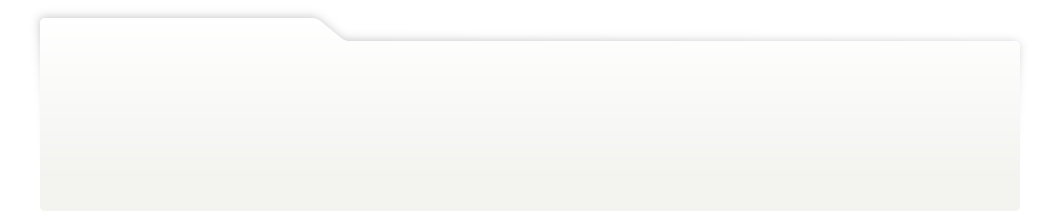
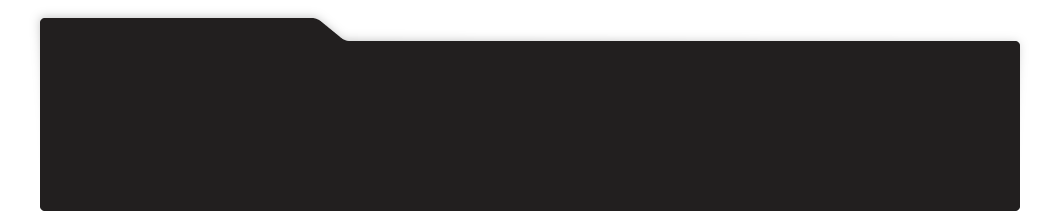
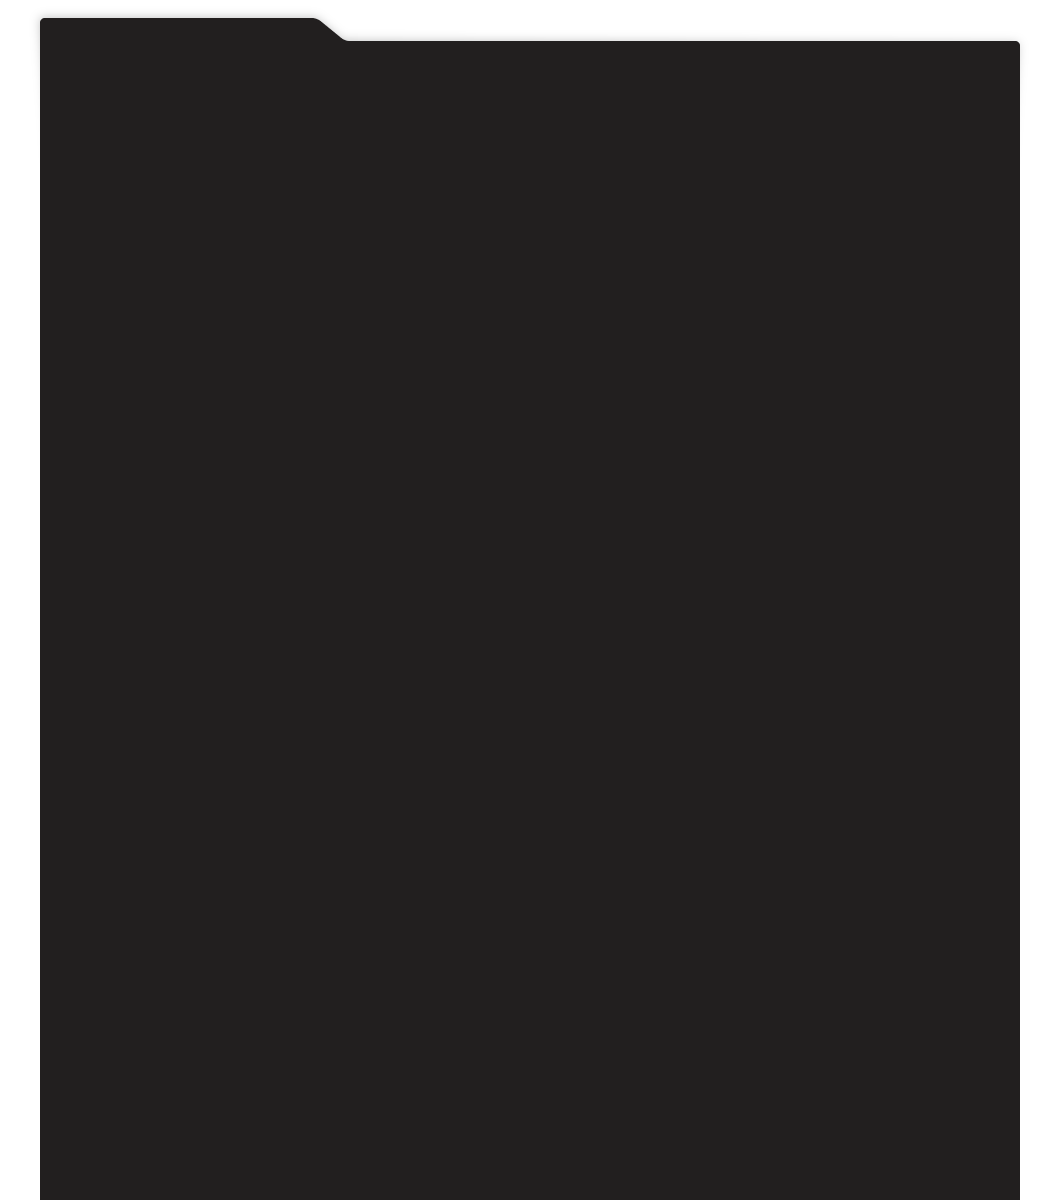
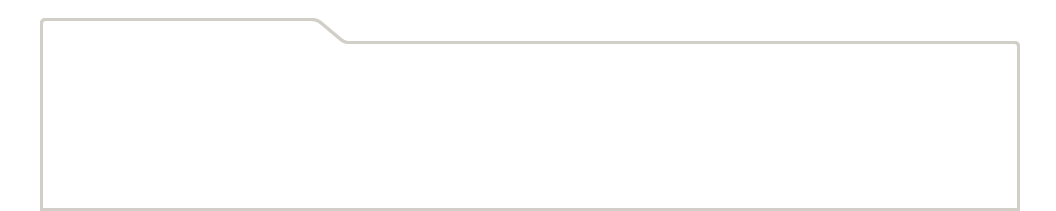
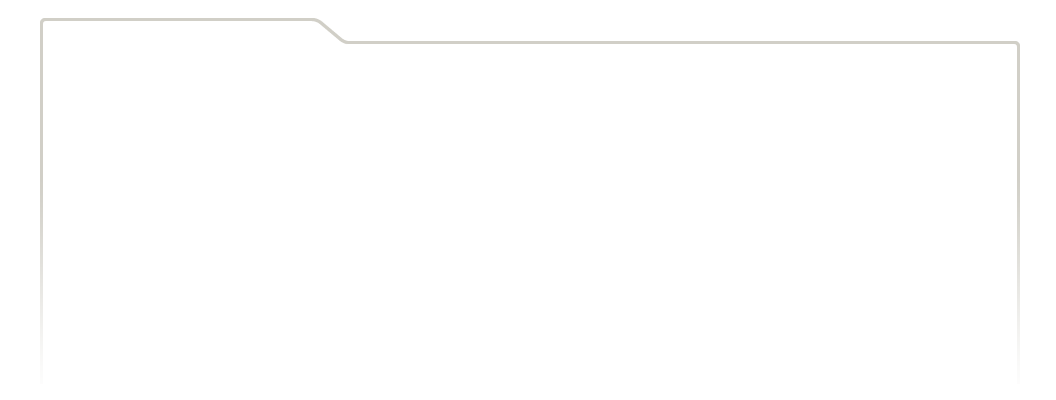
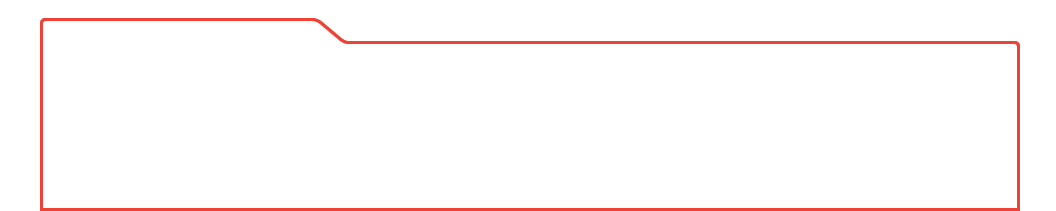
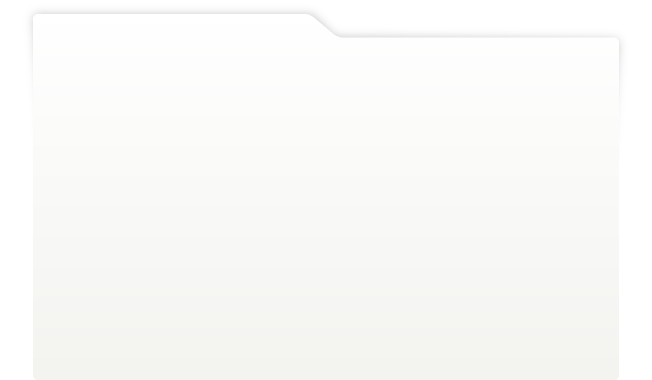
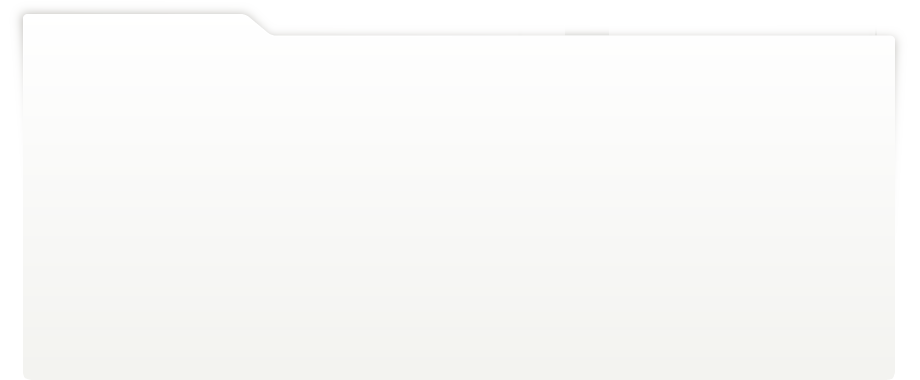
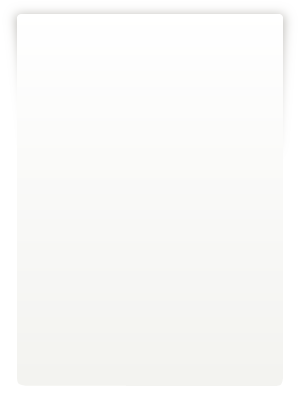
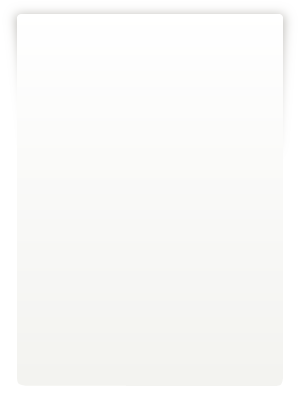
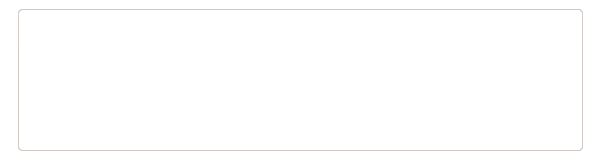
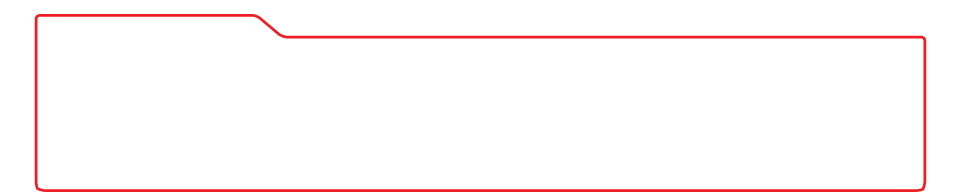
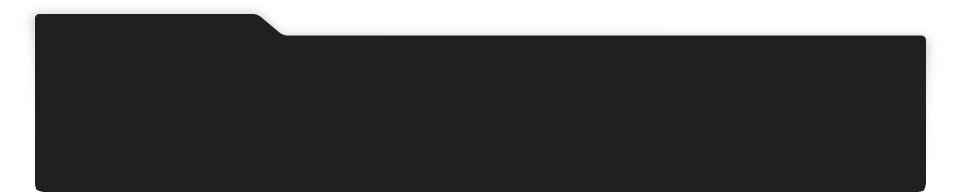
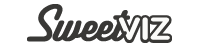
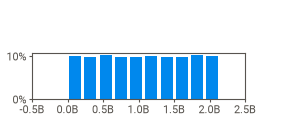
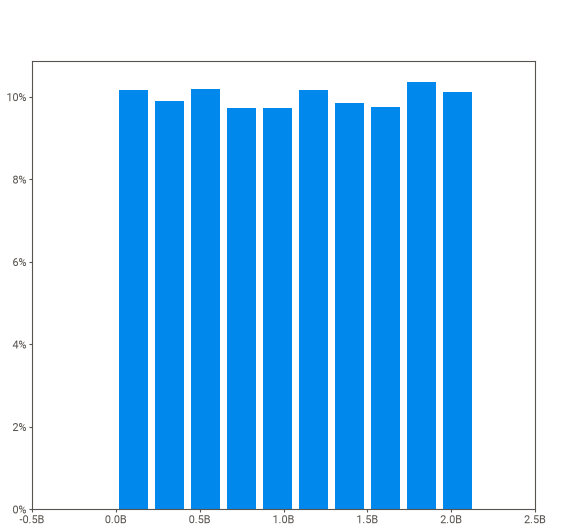
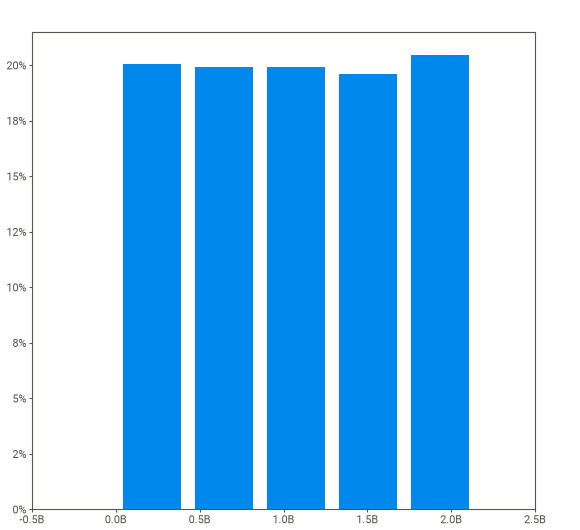
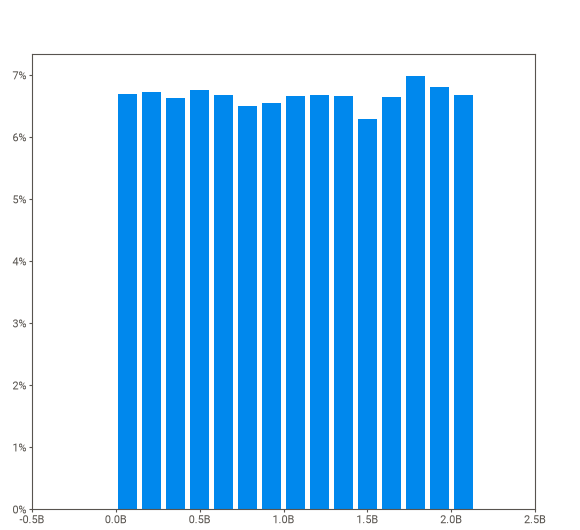
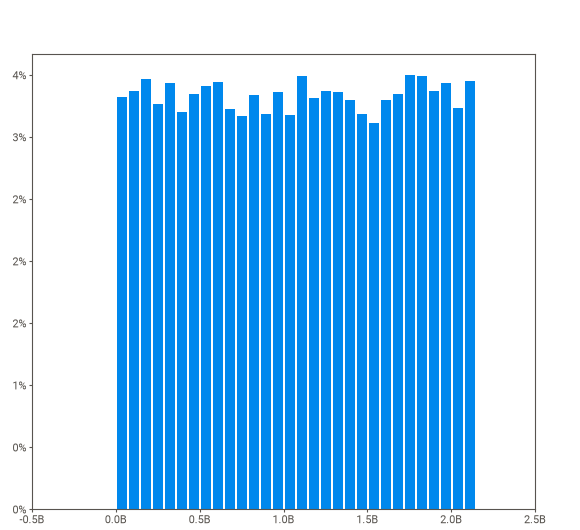
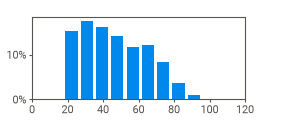
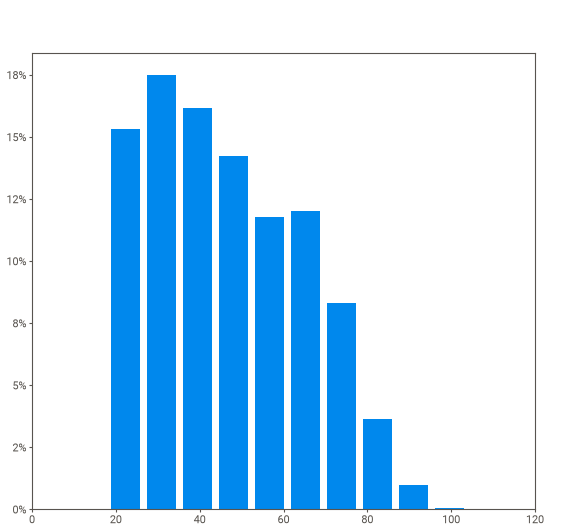
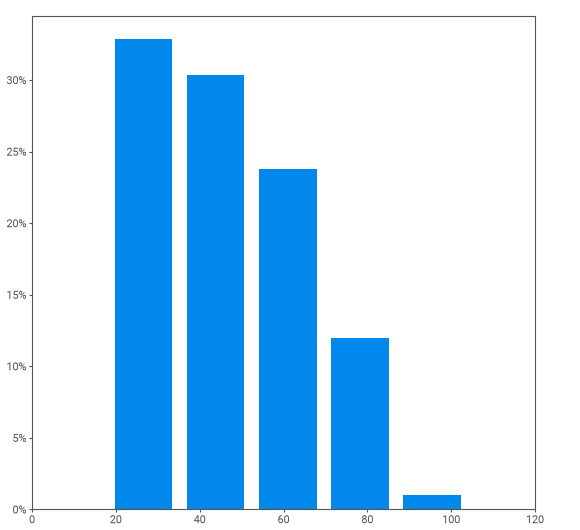
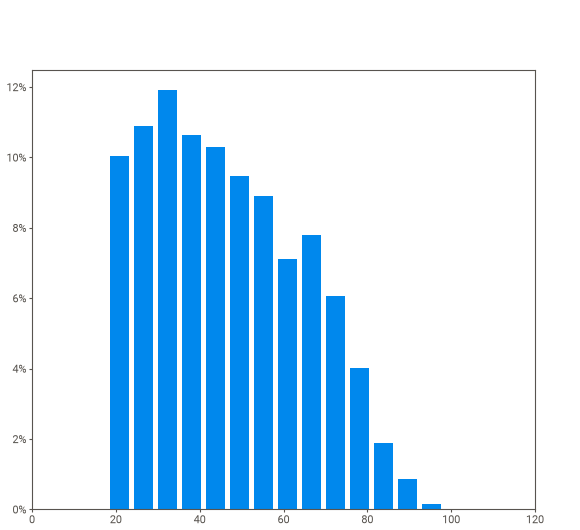
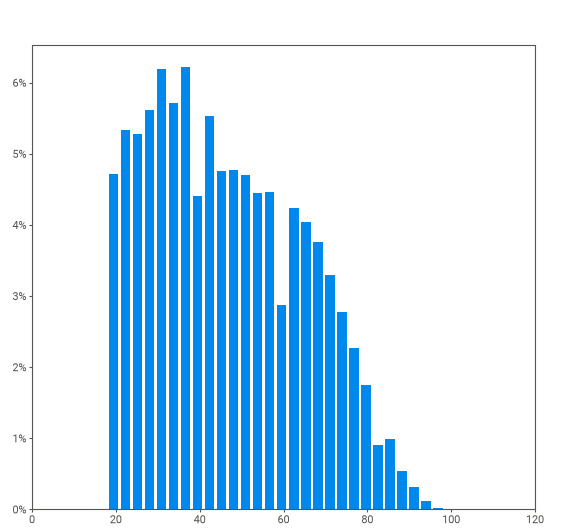
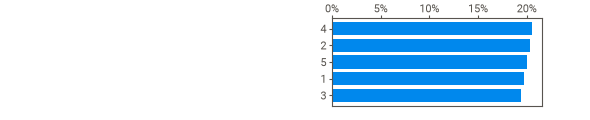
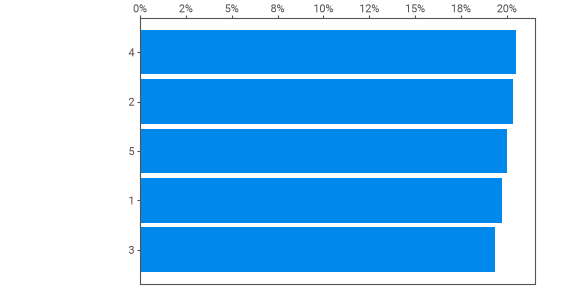
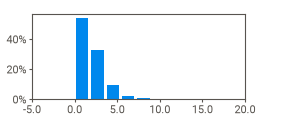
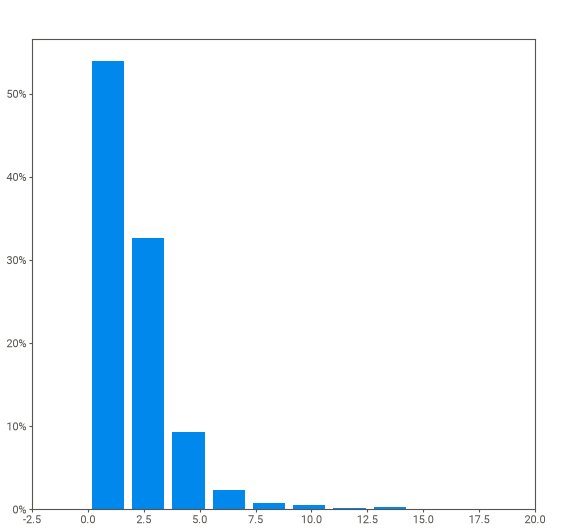
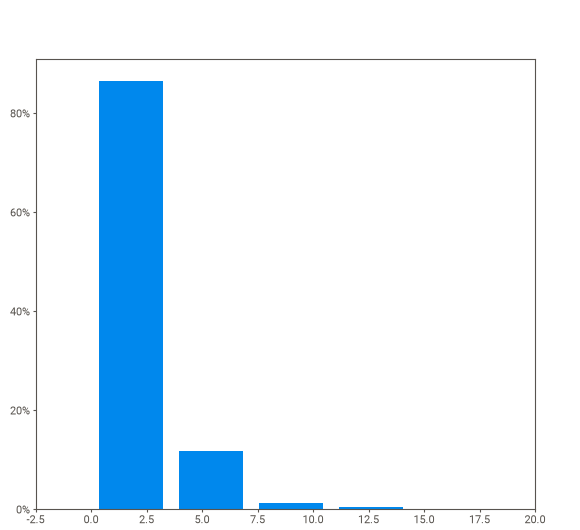
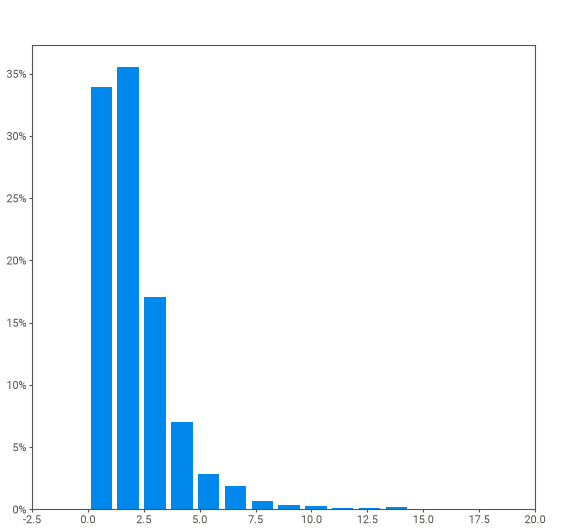
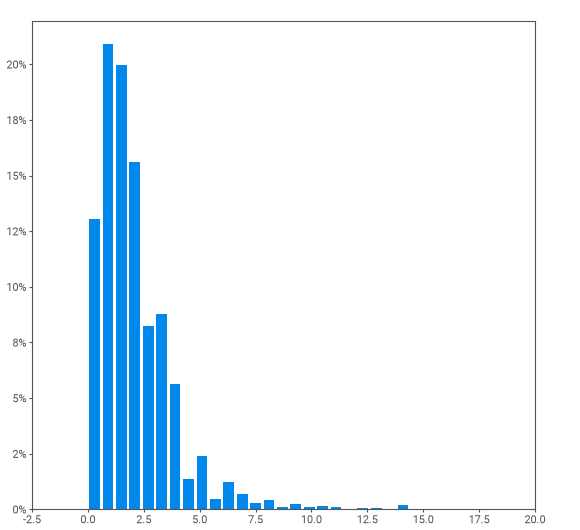
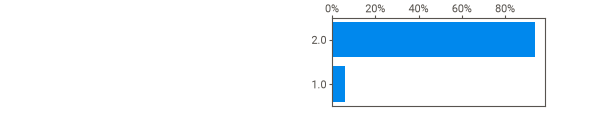
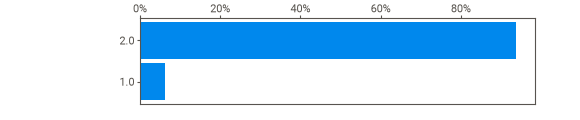
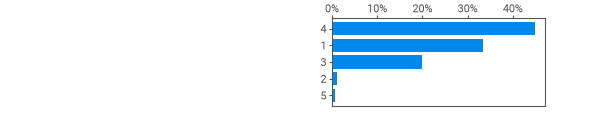
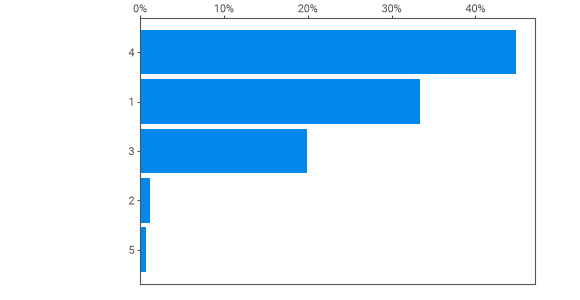
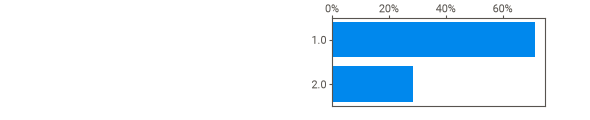
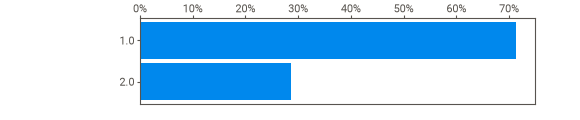
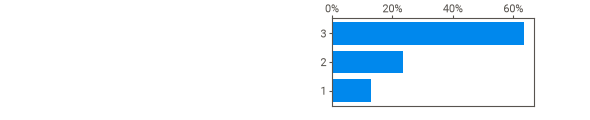
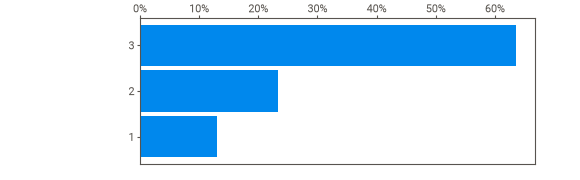
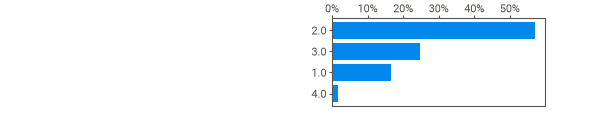
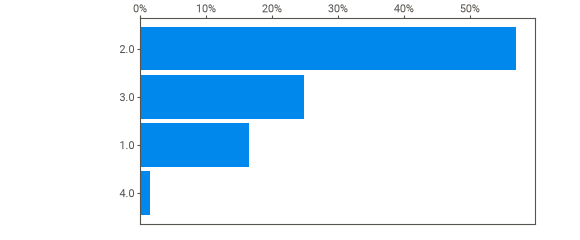
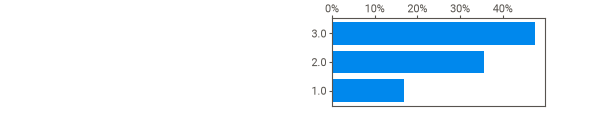
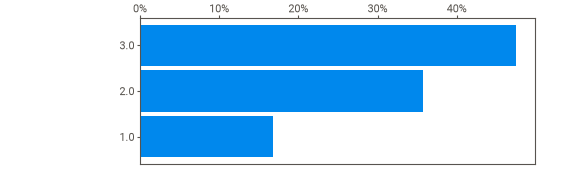
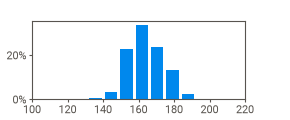
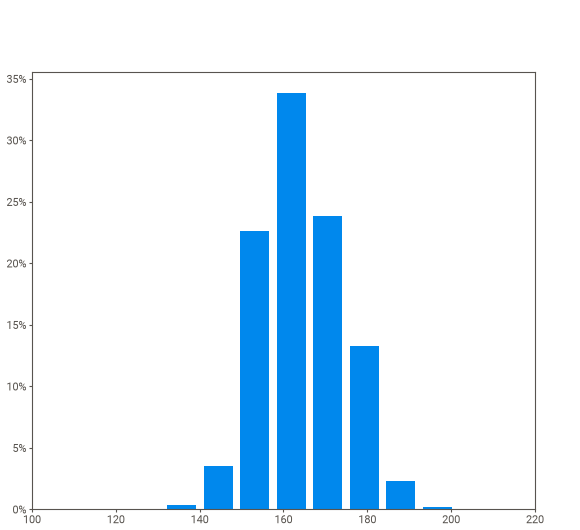
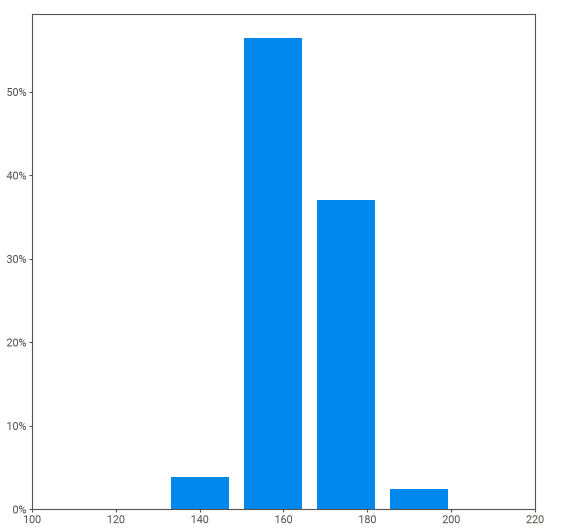
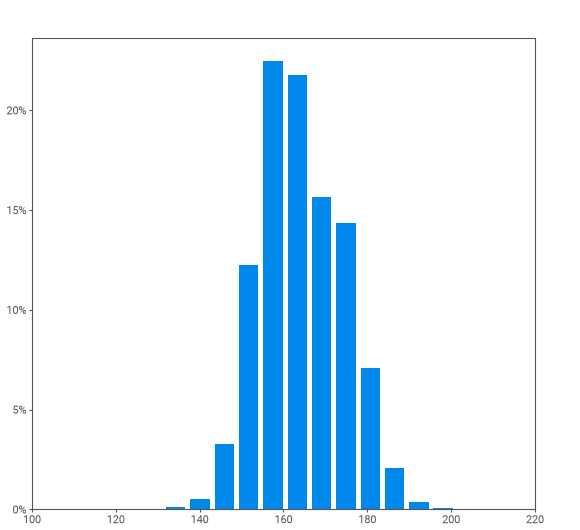
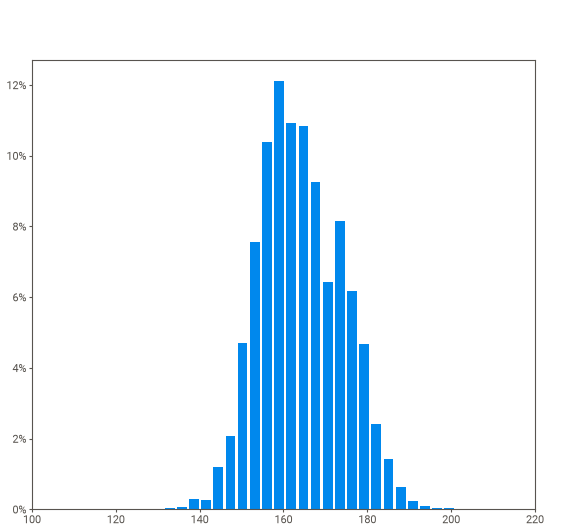
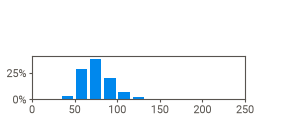
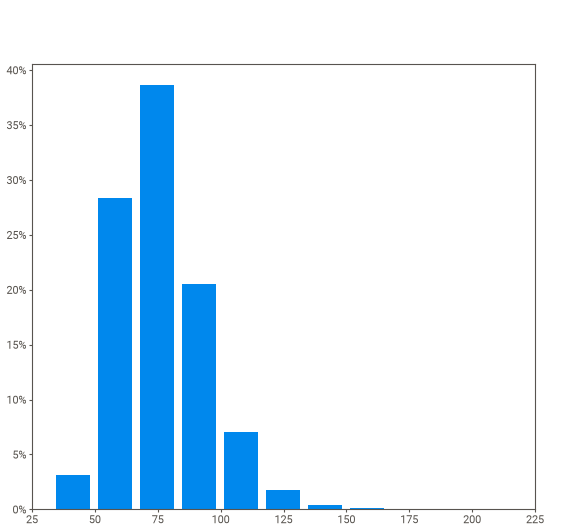
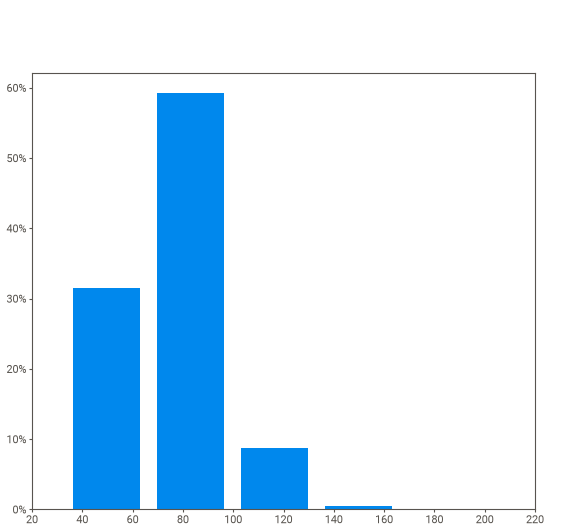
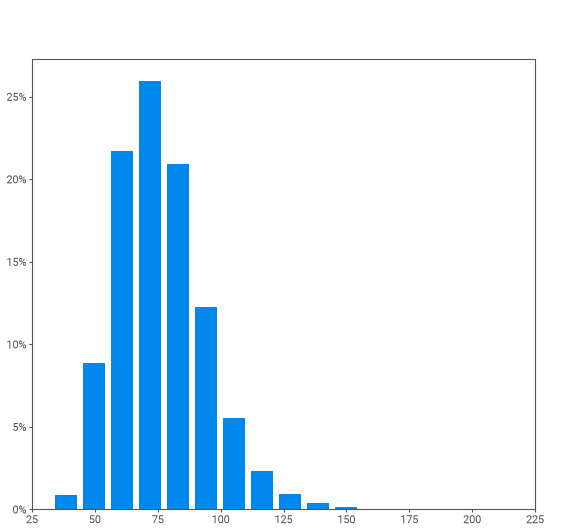
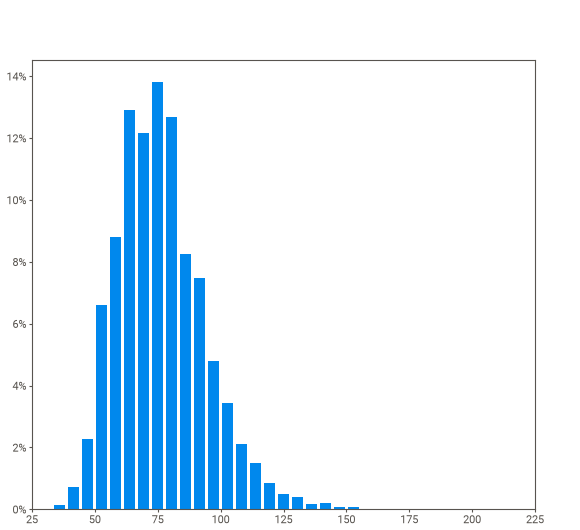
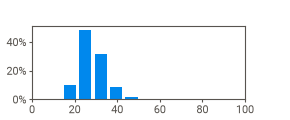
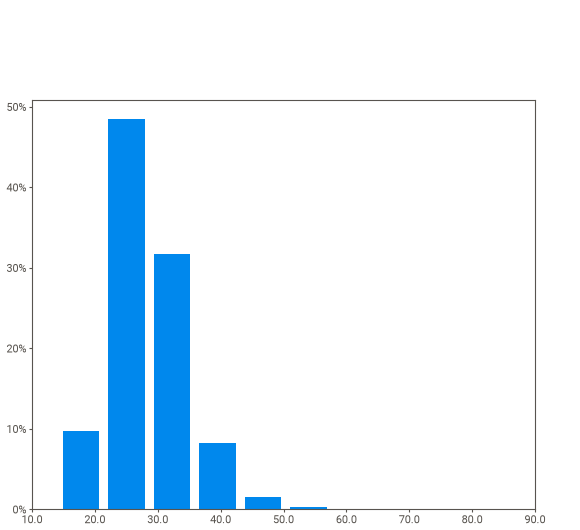
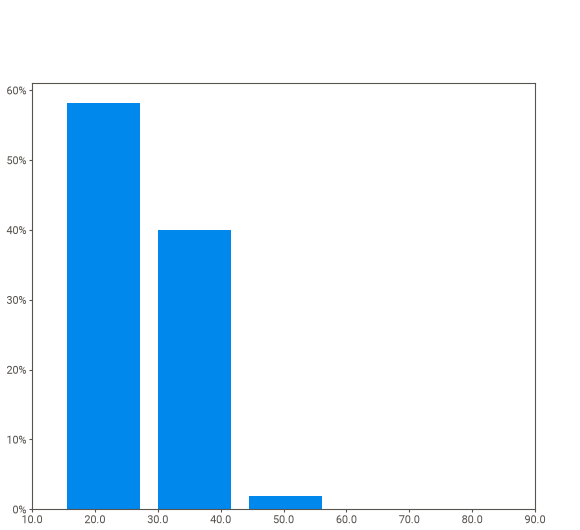
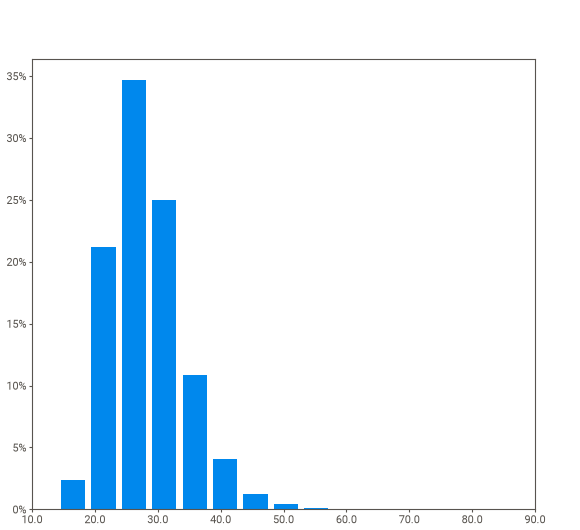
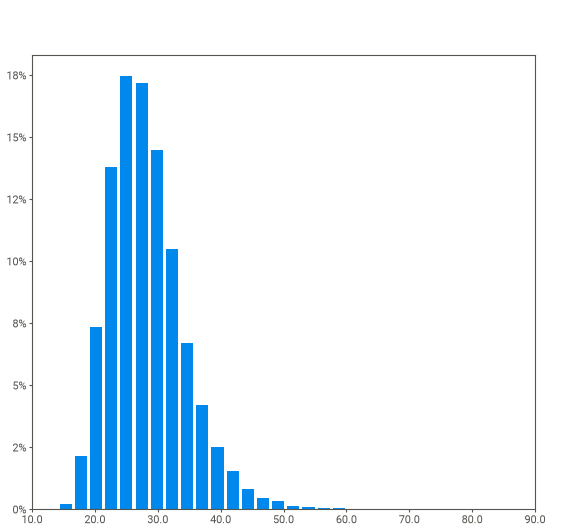
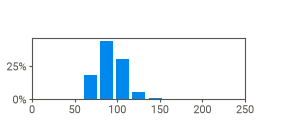
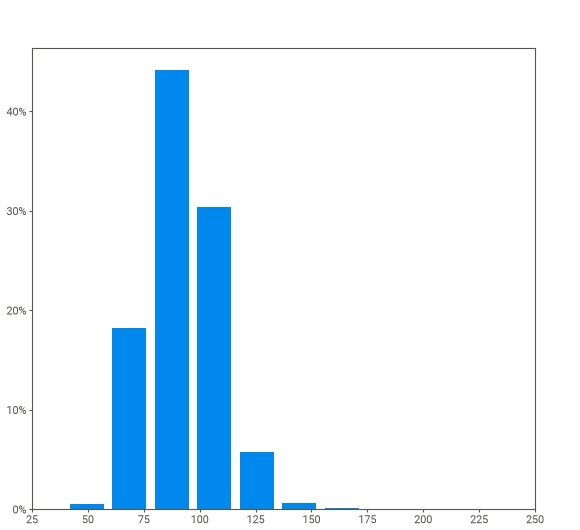
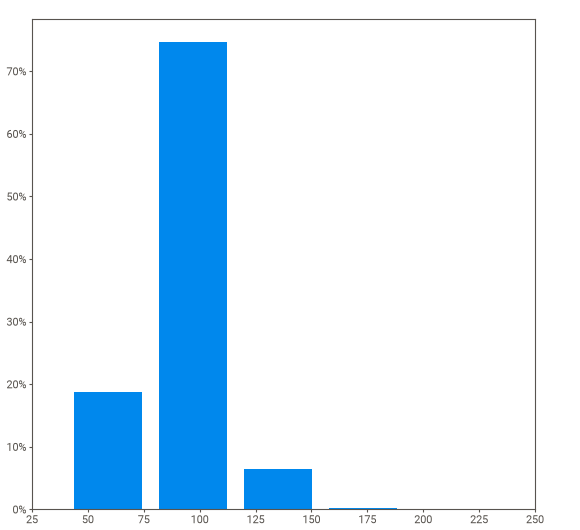
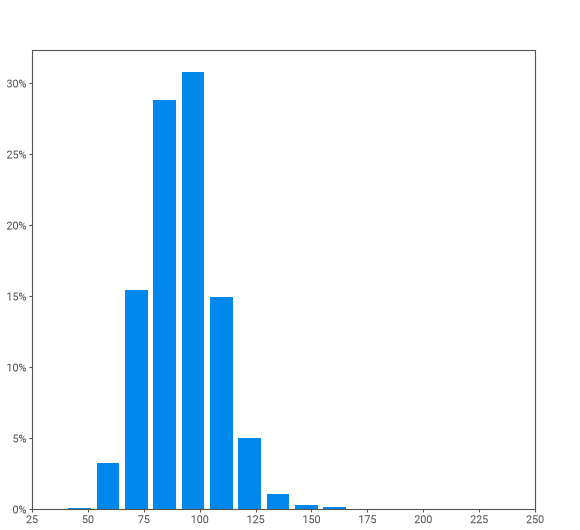
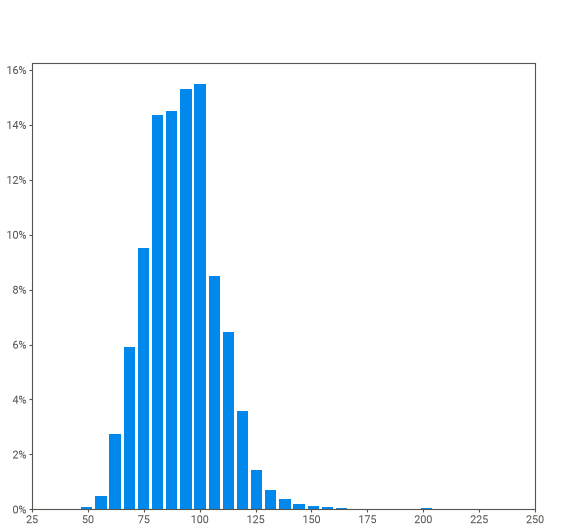
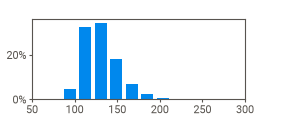
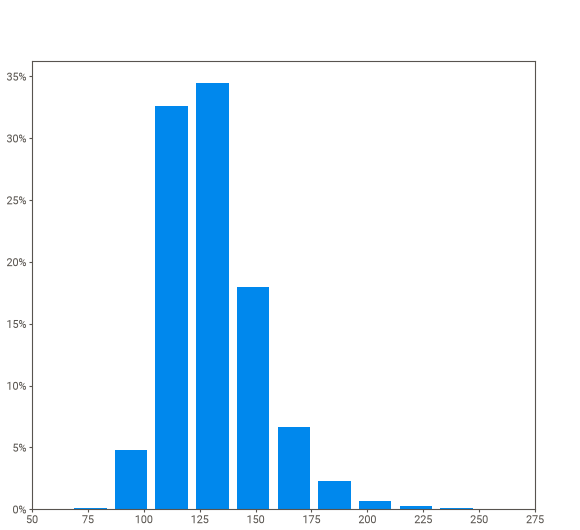
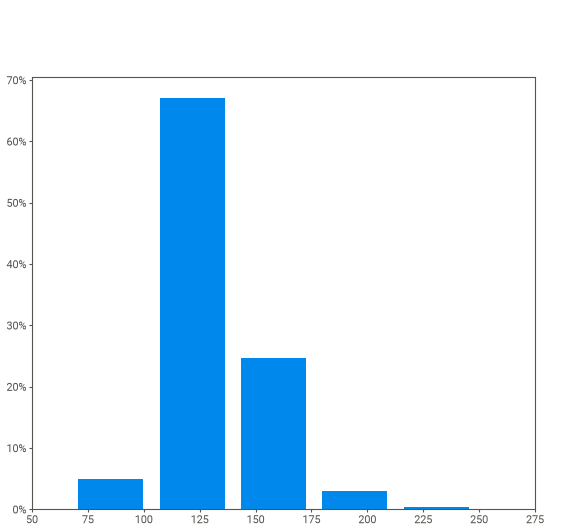
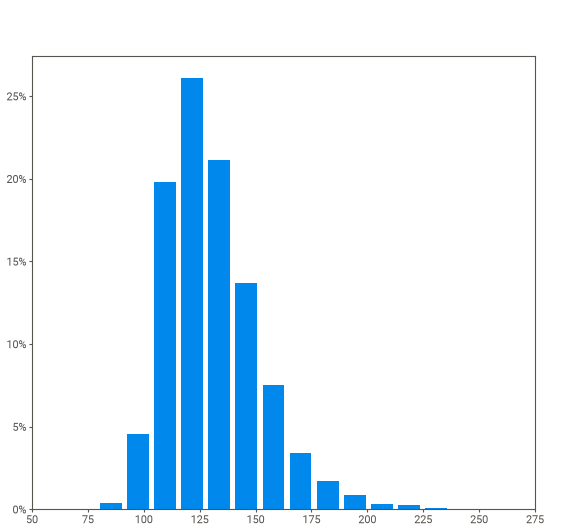
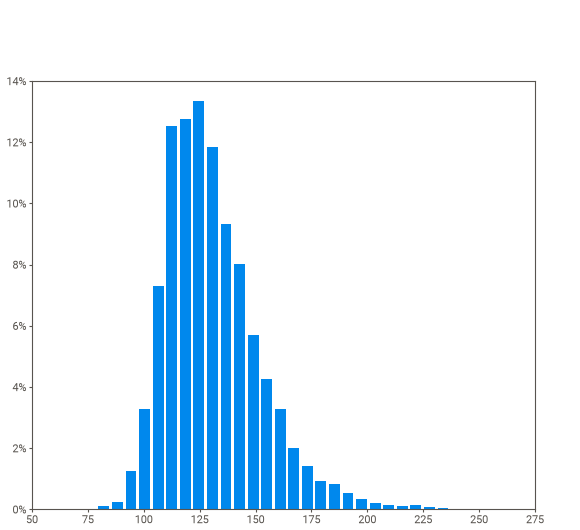
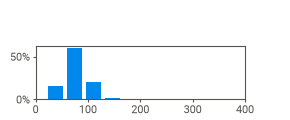
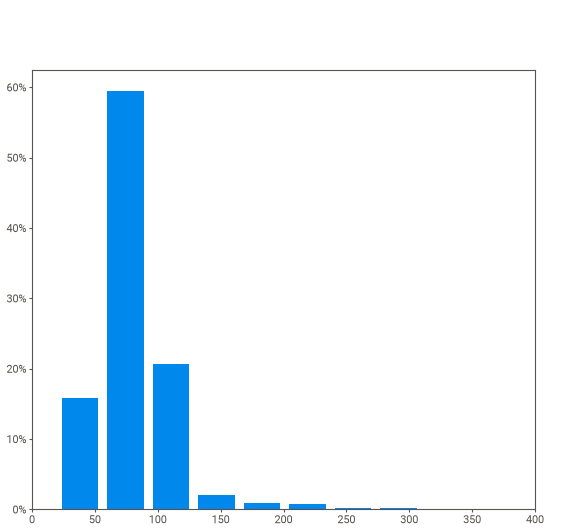
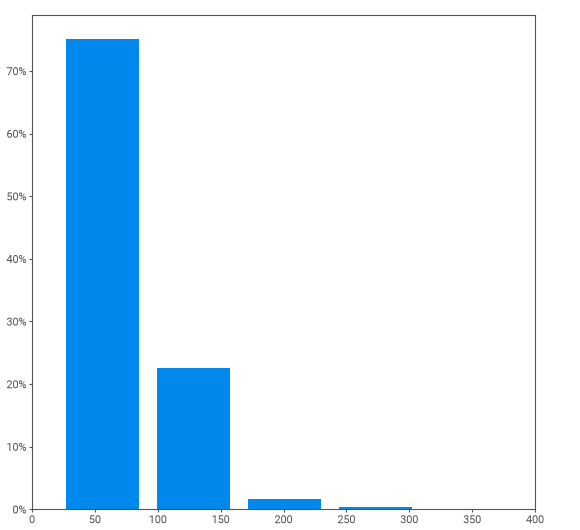
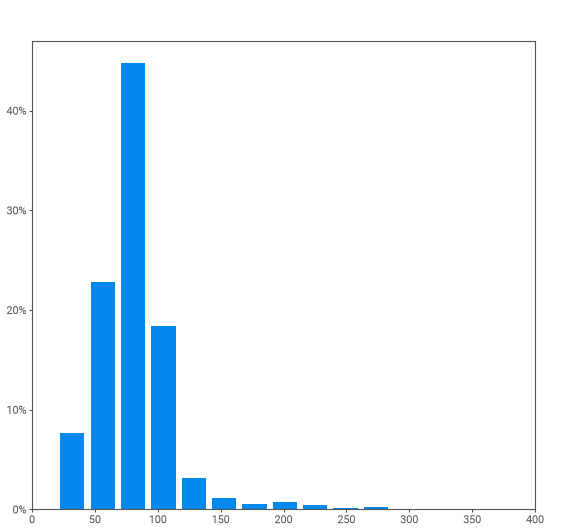
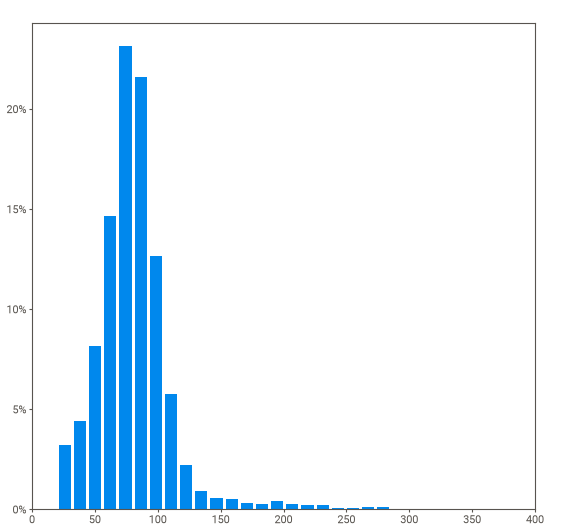
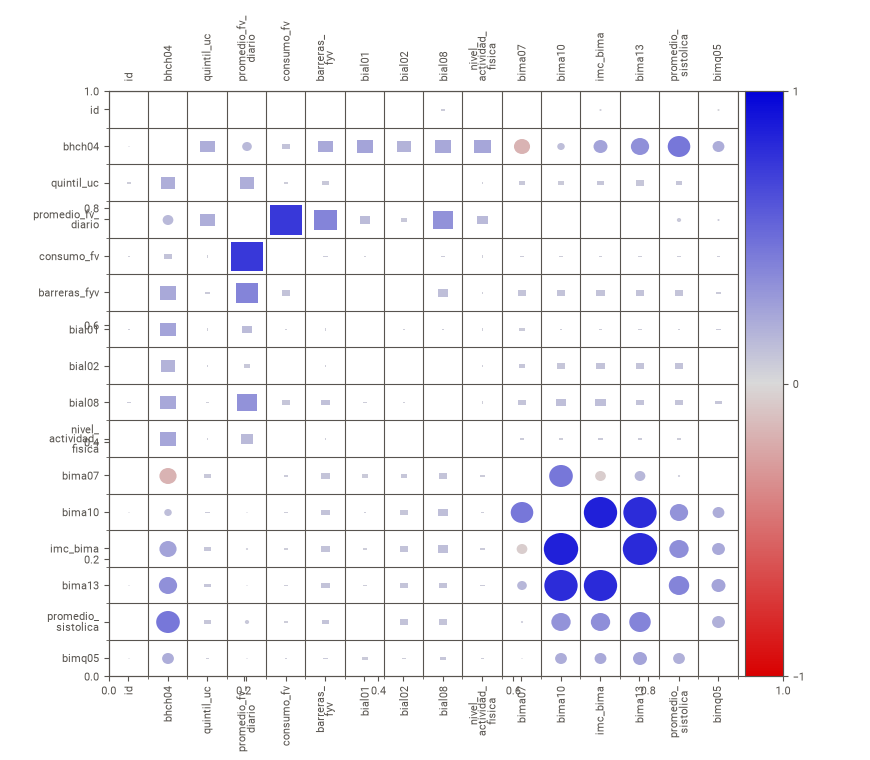
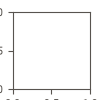

In [9]:
preprocessed_dataset = preprocessed_dataset.replace({pd.NA: np.nan})
reporte = sv.analyze(preprocessed_dataset)
reporte.show_notebook()

## 4.0) Detecion de outliers

In [10]:
vars_cuantitativas = [
    "bhch04", "promedio_fv_diario", "bima07", "bima10",
    "imc_bima", "bima13", "promedio_sistolica", "bimq05"
]

Q1 = preprocessed_dataset[vars_cuantitativas].quantile(0.25)
Q3 = preprocessed_dataset[vars_cuantitativas].quantile(0.75)
IQR = Q3 - Q1

outliers = (preprocessed_dataset[vars_cuantitativas] < (Q1 - 1.5 * IQR)) | (preprocessed_dataset[vars_cuantitativas] > (Q3 + 1.5 * IQR))

tabla_outliers = pd.DataFrame({
    "Cantidad de Outliers": outliers.sum(),
    "Porcentaje (%)": (outliers.mean() * 100).round(2),
    "Presencia de Outliers": outliers.sum() > 0
})

tabla_outliers

,Cantidad de Outliers,Porcentaje (%),Presencia de Outliers
bhch04,0,0.00,False
promedio_fv_diario,1206,4.13,True
bima07,41,0.14,True
bima10,301,1.03,True
imc_bima,343,1.17,True
bima13,170,0.58,True
promedio_sistolica,456,1.56,True
bimq05,251,0.86,True


## 5.0) Analisis de Correlacion de pearson

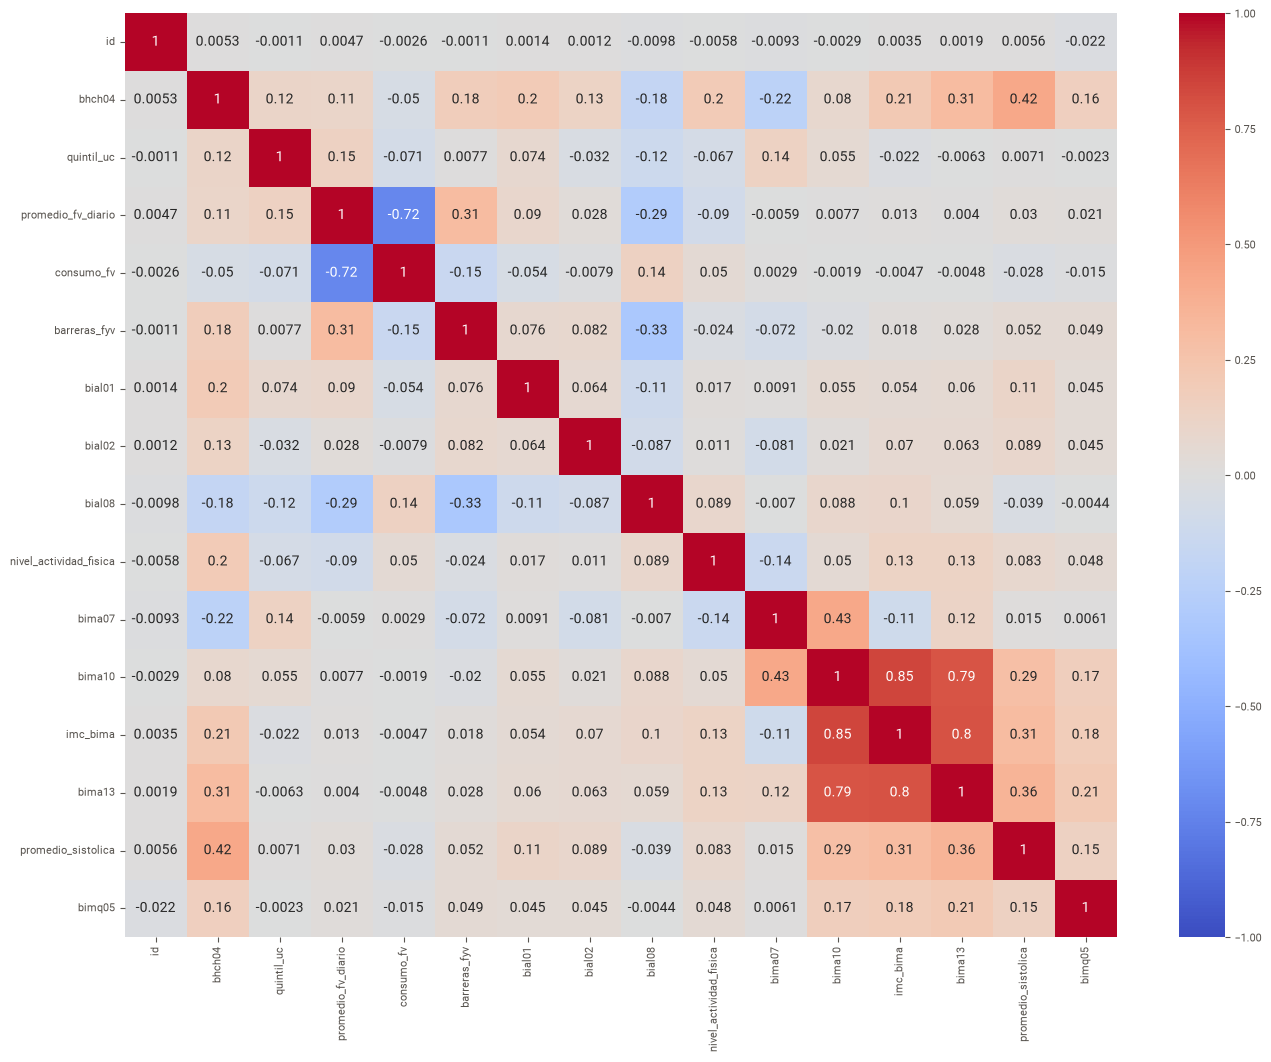

In [11]:
preprocessed_dataset = preprocessed_dataset.replace({pd.NA: np.nan})
correlation_matrix = preprocessed_dataset.corr()

plt.figure(figsize=(16,12))
sns.heatmap(correlation_matrix, vmin=-1.0, vmax=1.0, center=0.0, annot=True, cmap= 'coolwarm')
plt.show() 

# 6.0) Hipotesis propias

## 6.1) Hipotesis Univariada

In [12]:
etiquetas_sal = {
    1: "Siempre o casi siempre",
    2: "Raras veces",
    3: "Nunca"
}
conteo_sal = preprocessed_dataset['bial02'].value_counts().sort_index()
porcentaje_sal = (preprocessed_dataset['bial02'].value_counts(normalize=True).sort_index() * 100).round(2)
tabla_univariada = pd.DataFrame({
    "Habito de agregar sal en la mesa (bial02)": [etiquetas_sal[i] for i in conteo_sal.index],
    "N": conteo_sal.values,
    "Porcentaje (%)": porcentaje_sal.values,
    "% Acumulado": porcentaje_sal.cumsum().round(2).values
})
tabla_univariada

,Habito de agregar sal en la mesa (bial02),N,Porcentaje (%),% Acumulado
0,Siempre o casi siempre,3816,13.06,13.06
1,Raras veces,6825,23.35,36.41
2,Nunca,18583,63.59,100.00


## 6.2) Hipotesis Bivariada

In [13]:
df_biv = preprocessed_dataset[['quintil_uc', 'promedio_fv_diario']].dropna().copy()
df_biv['cumple_oms'] = (df_biv['promedio_fv_diario'] >= 5) * 100

grupos = df_biv.groupby('quintil_uc')

tabla_bivariada = pd.DataFrame({
    "N": grupos['promedio_fv_diario'].count(),
    "Media (porciones/día)": grupos['promedio_fv_diario'].mean().round(2),
    "Mediana": grupos['promedio_fv_diario'].median().round(2),
    "Desvio Estándar": grupos['promedio_fv_diario'].std().round(2),
    "Minimo": grupos['promedio_fv_diario'].min(),
    "Maximo": grupos['promedio_fv_diario'].max(),
    "% Cumple OMS (>=5)": grupos['cumple_oms'].mean().round(2)
}).reset_index()

tabla_bivariada

,quintil_uc,N,Media (porciones/día),Mediana,Desvio Estándar,Minimo,Maximo,% Cumple OMS (>=5)
0,1,5513,1.71,1.29,1.54,0.0,14.0,3.86
1,2,5778,1.91,1.43,1.61,0.0,17.0,5.07
2,3,5555,2.05,1.57,1.67,0.0,18.0,5.78
3,4,5867,2.24,1.86,1.80,0.0,17.0,7.52
4,5,5758,2.43,2.00,1.81,0.0,18.0,8.75


## 6.3) Hipotesis Multivariada

In [14]:
df_multi = preprocessed_dataset[['promedio_sistolica', 'bhch04', 'bima10', 'bima07', 'promedio_fv_diario']].dropna().copy()

df_multi['Grupo de Edad'] = pd.cut(df_multi['bhch04'], bins=[17, 44, 110], labels=['18 a 44 años', '45 o más años'])
df_multi['Rango de Peso'] = pd.cut(df_multi['bima10'], bins=[0, 69.99, 84.99, 250], labels=['Menor a 70 kg', '70 a 84.9 kg', '85 kg o más'])
df_multi['hipertension'] = (df_multi['promedio_sistolica'] >= 140) * 100

grupos_multi = df_multi.groupby(['Grupo de Edad', 'Rango de Peso'], observed=False)

tabla_multivariada = pd.DataFrame({
    "N": grupos_multi['promedio_sistolica'].count(),
    "Edad Media (años)": grupos_multi['bhch04'].mean().round(1),
    "Peso Medio (kg)": grupos_multi['bima10'].mean().round(1),
    "Talla Media (cm)": grupos_multi['bima07'].mean().round(1),
    "Media F&V (porc/día)": grupos_multi['promedio_fv_diario'].mean().round(2),
    "Media Sistólica (mmHg)": grupos_multi['promedio_sistolica'].mean().round(2),
    "Mediana Sistólica": grupos_multi['promedio_sistolica'].median().round(1),
    "Desvío Estándar": grupos_multi['promedio_sistolica'].std().round(2),
    "% Presión >=140 mmHg": grupos_multi['hipertension'].mean().round(2)
}).reset_index()

tabla_multivariada

,Grupo de Edad,Rango de Peso,N,Edad Media (años),Peso Medio (kg),Talla Media (cm),Media F&V (porc/día),Media Sistólica (mmHg),Mediana Sistólica,Desvío Estándar,% Presión >=140 mmHg
0,18 a 44 años,Menor a 70 kg,3487,29.6,59.4,161.8,1.93,116.69,115.0,13.40,5.51
1,18 a 44 años,70 a 84.9 kg,2462,31.8,76.4,167.8,1.83,124.37,123.0,14.54,13.36
2,18 a 44 años,85 kg o más,2009,33.5,98.3,170.8,1.82,130.57,128.5,15.72,24.89
3,45 o más años,Menor a 70 kg,2562,63.2,60.7,157.1,2.16,134.32,131.0,22.97,35.25
4,45 o más años,70 a 84.9 kg,2732,61.8,76.8,162.5,2.21,139.16,136.0,21.96,43.63
5,45 o más años,85 kg o más,2379,59.5,97.5,167.9,2.21,143.37,140.5,21.36,52.04


## 7.0) Planteo de pruebas para hipotesis univariadas

7.1) Hipotesis univariada propia(bial02)

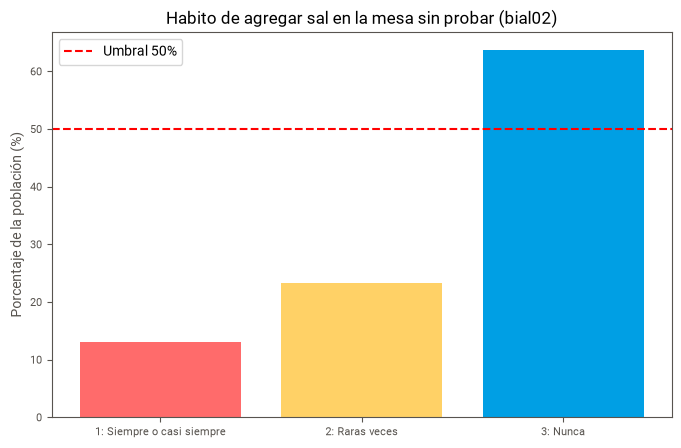

Proporcion observada que 'Nunca' agrega sal: 63.59%
Test de Kolmogorov Smirnov: Estadistico=0.500, p-valor=0.0000e+00
Se rechaza normalidad (p < 0.05): se aplica Prueba de Wilcoxon para 1 muestra 
Resultado del test: estadistico=271544087.5, p-valor=0.0000e+00
Conclusion: Se rechaza H0, se confirma que más del 50% de la poblacion nunca agrega sal en la mesa.


In [15]:
sal_mesa = preprocessed_dataset['bial02'].dropna()

porcentajes_sal = (sal_mesa.value_counts(normalize=True).sort_index() * 100)
categorias = ["1: Siempre o casi siempre", "2: Raras veces", "3: Nunca"]

plt.figure(figsize=(8, 5))
plt.bar(categorias, porcentajes_sal.values, color=['#FF6B6B', '#FFD166', '#009FE4'])
plt.axhline(50, color='red', linestyle='--', label='Umbral 50%')
plt.title("Habito de agregar sal en la mesa sin probar (bial02)")
plt.ylabel("Porcentaje de la población (%)")
plt.legend()
plt.show()

es_nunca = (sal_mesa == 3).astype(int)
stat_ks, p_norm = stats.kstest(es_nunca, 'norm')
print(f"Proporcion observada que 'Nunca' agrega sal: {es_nunca.mean()*100:.2f}%")
print(f"Test de Kolmogorov Smirnov: Estadistico={stat_ks:.3f}, p-valor={p_norm:.4e}")

if p_norm >= 0.05:
    print("No se rechaza normalidad: se aplica Test t para 1 muestra")
    stat_test, p_valor = stats.ttest_1samp(es_nunca, popmean=0.50, alternative='greater')
else:
    print("Se rechaza normalidad (p < 0.05): se aplica Prueba de Wilcoxon para 1 muestra ")
    stat_test, p_valor = stats.wilcoxon(es_nunca - 0.50, alternative='greater')
print(f"Resultado del test: estadistico={stat_test:.1f}, p-valor={p_valor:.4e}")
if p_valor < 0.05:
    print("Conclusion: Se rechaza H0, se confirma que más del 50% de la poblacion nunca agrega sal en la mesa.")
else:
    print("Conclusion: No se rechaza H0, no hay evidencia suficiente para afirmar que supere el 50%.")

7.2) Hipotesis univariada de la catedra(promedio_fv_diario)

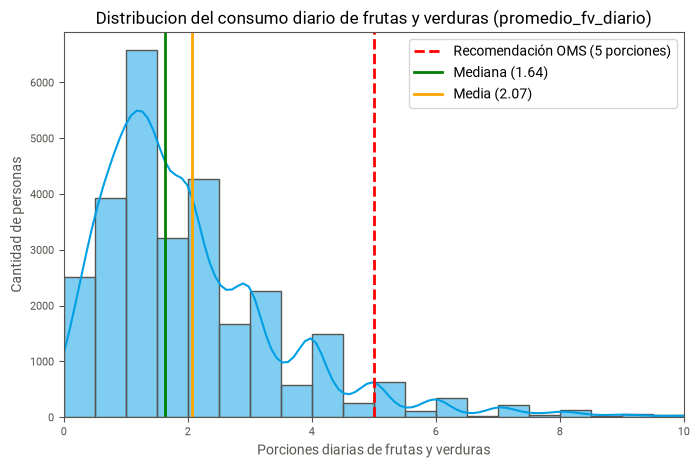

Media observada: 2.07 | Mediana observada: 1.64
Test de Kolmogorov Smirnov: Estadistico=0.628, p-valor=0.0000e+00
Se rechaza normalidad (p < 0.05): se aplica Prueba de Wilcoxon para 1 muestra
Resultado del test: estadistico=11004585.0, p-valor=0.0000e+00
Conclusion: Se rechaza H0, se confirma que el consumo diario es significativamente menor a 5 porciones.


In [16]:
fv_diario = preprocessed_dataset['promedio_fv_diario'].dropna()

plt.figure(figsize=(8, 5))
sns.histplot(fv_diario, binwidth=0.5, binrange=(0, 10), kde=True, color='#009FE4')
plt.axvline(5.0, color='red', linestyle='--', linewidth=2, label='Recomendación OMS (5 porciones)')
plt.axvline(fv_diario.median(), color='green', linestyle='-', linewidth=2, label=f'Mediana ({fv_diario.median():.2f})')
plt.axvline(fv_diario.mean(), color='orange', linestyle='-', linewidth=2, label=f'Media ({fv_diario.mean():.2f})')
plt.xlim(0, 10)
plt.title("Distribucion del consumo diario de frutas y verduras (promedio_fv_diario)")
plt.xlabel("Porciones diarias de frutas y verduras")
plt.ylabel("Cantidad de personas")
plt.legend()
plt.show()

stat_ks, p_norm = stats.kstest(fv_diario, 'norm')
print(f"Media observada: {fv_diario.mean():.2f} | Mediana observada: {fv_diario.median():.2f}")
print(f"Test de Kolmogorov Smirnov: Estadistico={stat_ks:.3f}, p-valor={p_norm:.4e}")


if p_norm >= 0.05:
    print("No se rechaza normalidad: se aplica Test t para 1 muestra")
    stat_test, p_valor = stats.ttest_1samp(fv_diario, popmean=5.0, alternative='less')
else:
    print("Se rechaza normalidad (p < 0.05): se aplica Prueba de Wilcoxon para 1 muestra")
    stat_test, p_valor = stats.wilcoxon(fv_diario - 5.0, alternative='less')
print(f"Resultado del test: estadistico={stat_test:.1f}, p-valor={p_valor:.4e}")
if p_valor < 0.05:
    print("Conclusion: Se rechaza H0, se confirma que el consumo diario es significativamente menor a 5 porciones.")
else:
    print("Conclusion: No se rechaza H0, no hay evidencia suficiente para afirmar que sea menor a 5 porciones.")

## 8.0) Planteo de pruebas para hipotesis bivariadas

8.1) Hipotesis bivariada propia(quintil_uc y promedio_fv_diario)

C:\Users\facun\AppData\Local\Temp\ipykernel_4312\592239604.py:4: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(


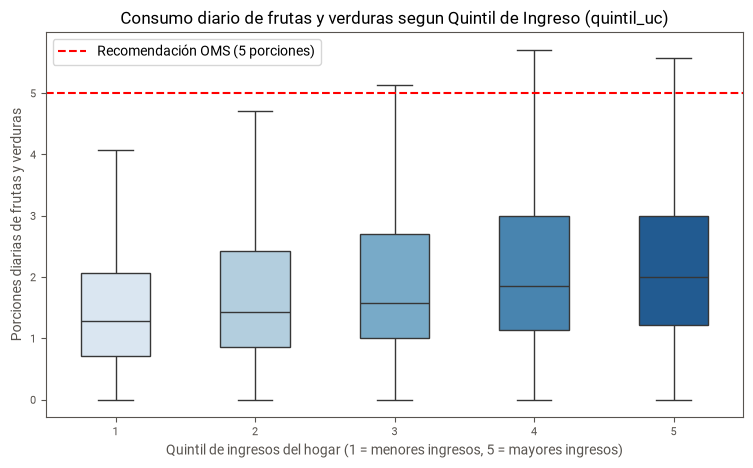

p-valores Kolmogorov Smirnov por quintil: Q1=0.00e+00, Q2=0.00e+00, Q3=0.00e+00, Q4=0.00e+00, Q5=0.00e+00
Test de Levene (homocedasticidad): estadistico=37.35, p-valor=3.3200e-31
No se cumplen normalidad/homocedasticidad: se aplica Prueba de Kruskal Wallis
Resultado del test: estadistico=940.75, p-valor=2.4727e-202
Conclusion: Se rechaza H0, al menos un quintil presenta una distribución de consumo significativamente distinta.


In [17]:
df_biv1 = preprocessed_dataset[['quintil_uc', 'promedio_fv_diario']].dropna()

plt.figure(figsize=(9, 5))
sns.boxplot(
    data=df_biv1,
    x='quintil_uc',
    y='promedio_fv_diario',
    palette='Blues',
    width=0.5,
    showfliers=False
)
plt.axhline(5.0, color='red', linestyle='--', linewidth=1.5, label='Recomendación OMS (5 porciones)')
plt.title("Consumo diario de frutas y verduras segun Quintil de Ingreso (quintil_uc)")
plt.xlabel("Quintil de ingresos del hogar (1 = menores ingresos, 5 = mayores ingresos)")
plt.ylabel("Porciones diarias de frutas y verduras")
plt.legend()
plt.show()

q1 = df_biv1[df_biv1['quintil_uc'] == 1]['promedio_fv_diario']
q2 = df_biv1[df_biv1['quintil_uc'] == 2]['promedio_fv_diario']
q3 = df_biv1[df_biv1['quintil_uc'] == 3]['promedio_fv_diario']
q4 = df_biv1[df_biv1['quintil_uc'] == 4]['promedio_fv_diario']
q5 = df_biv1[df_biv1['quintil_uc'] == 5]['promedio_fv_diario']

stat_ks1, p_norm1 = stats.kstest(q1, 'norm')
stat_ks2, p_norm2 = stats.kstest(q2, 'norm')
stat_ks3, p_norm3 = stats.kstest(q3, 'norm')
stat_ks4, p_norm4 = stats.kstest(q4, 'norm')
stat_ks5, p_norm5 = stats.kstest(q5, 'norm')
es_normal = (p_norm1 >= 0.05) and (p_norm2 >= 0.05) and (p_norm3 >= 0.05) and (p_norm4 >= 0.05) and (p_norm5 >= 0.05)
print(f"p-valores Kolmogorov Smirnov por quintil: Q1={p_norm1:.2e}, Q2={p_norm2:.2e}, Q3={p_norm3:.2e}, Q4={p_norm4:.2e}, Q5={p_norm5:.2e}")

stat_levene, p_levene = stats.levene(q1, q2, q3, q4, q5)
es_homocedastico = p_levene >= 0.05
print(f"Test de Levene (homocedasticidad): estadistico={stat_levene:.2f}, p-valor={p_levene:.4e}")

if es_normal and es_homocedastico:
    print("Se cumplen normalidad y homocedasticidad: se aplica ANOVA de 1 via")
    stat_test, p_valor = stats.f_oneway(q1, q2, q3, q4, q5)
else:
    print("No se cumplen normalidad/homocedasticidad: se aplica Prueba de Kruskal Wallis")
    stat_test, p_valor = stats.kruskal(q1, q2, q3, q4, q5)
print(f"Resultado del test: estadistico={stat_test:.2f}, p-valor={p_valor:.4e}")
if p_valor < 0.05:
    print("Conclusion: Se rechaza H0, al menos un quintil presenta una distribución de consumo significativamente distinta.")
else:
    print("Conclusion: No se rechaza H0, no hay evidencia suficiente para afirmar que haya diferencias significativas entre los quintiles.")

8.2) Hipotesis bivariada de la catedra(imc_bima y nivel_actividad_fisica)

C:\Users\facun\AppData\Local\Temp\ipykernel_4312\1108737142.py:4: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(


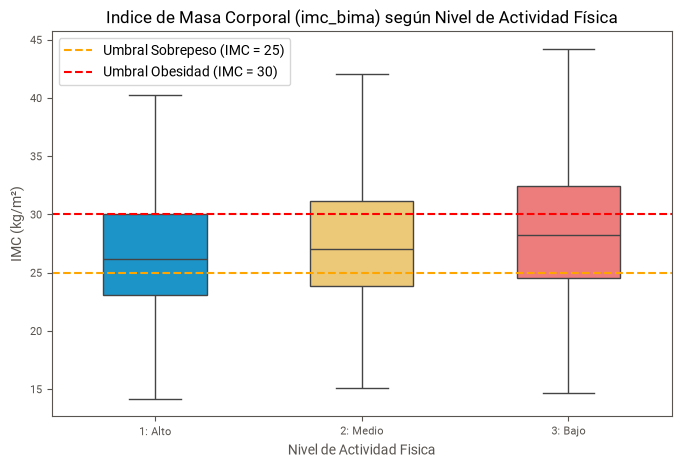

Mediana IMC -> Alto: 26.15 | Medio: 27.06 | Bajo: 28.23
Media IMC   -> Alto: 26.95 | Medio: 27.83 | Bajo: 28.99
p-valores Kolmogorov Smirnov: Alto=0.00e+00, Medio=0.00e+00, Bajo=0.00e+00
No se cumplen normalidad/homocedasticidad: se aplica Prueba de Kruskal Wallis
Resultado del test: estadistico=271.83, p-valor=9.3805e-60
Conclusion: Se rechaza H0, el IMC difiere significativamente según el nivel de actividad física.


In [18]:
df_biv2 = preprocessed_dataset[['nivel_actividad_fisica', 'imc_bima']].dropna()

plt.figure(figsize=(8, 5))
sns.boxplot(
    data=df_biv2,
    x='nivel_actividad_fisica',
    y='imc_bima',
    palette=['#009FE4', '#FFD166', '#FF6B6B'],
    width=0.5,
    showfliers=False
)
plt.xticks([0, 1, 2], ["1: Alto", "2: Medio", "3: Bajo"])
plt.axhline(25.0, color='orange', linestyle='--', linewidth=1.5, label='Umbral Sobrepeso (IMC = 25)')
plt.axhline(30.0, color='red', linestyle='--', linewidth=1.5, label='Umbral Obesidad (IMC = 30)')
plt.title("Indice de Masa Corporal (imc_bima) según Nivel de Actividad Física")
plt.xlabel("Nivel de Actividad Fisica")
plt.ylabel("IMC (kg/m²)")
plt.legend()
plt.show()

af_alto  = df_biv2[df_biv2['nivel_actividad_fisica'] == 1]['imc_bima']
af_medio = df_biv2[df_biv2['nivel_actividad_fisica'] == 2]['imc_bima']
af_bajo  = df_biv2[df_biv2['nivel_actividad_fisica'] == 3]['imc_bima']
print(f"Mediana IMC -> Alto: {af_alto.median():.2f} | Medio: {af_medio.median():.2f} | Bajo: {af_bajo.median():.2f}")
print(f"Media IMC   -> Alto: {af_alto.mean():.2f} | Medio: {af_medio.mean():.2f} | Bajo: {af_bajo.mean():.2f}")

stat_ks1, p_norm1 = stats.kstest(af_alto, 'norm')
stat_ks2, p_norm2 = stats.kstest(af_medio, 'norm')
stat_ks3, p_norm3 = stats.kstest(af_bajo, 'norm')
es_normal = (p_norm1 >= 0.05) and (p_norm2 >= 0.05) and (p_norm3 >= 0.05)
print(f"p-valores Kolmogorov Smirnov: Alto={p_norm1:.2e}, Medio={p_norm2:.2e}, Bajo={p_norm3:.2e}")

stat_levene, p_levene = stats.levene(af_alto, af_medio, af_bajo)
es_homocedastico = p_levene >= 0.05
if es_normal and es_homocedastico:
    print("Se cumplen normalidad y homocedasticidad: se aplica ANOVA de 1 via")
    stat_test, p_valor = stats.f_oneway(af_alto, af_medio, af_bajo)
else:
    print("No se cumplen normalidad/homocedasticidad: se aplica Prueba de Kruskal Wallis")
    stat_test, p_valor = stats.kruskal(af_alto, af_medio, af_bajo)
print(f"Resultado del test: estadistico={stat_test:.2f}, p-valor={p_valor:.4e}")
if p_valor < 0.05:
    print("Conclusion: Se rechaza H0, el IMC difiere significativamente según el nivel de actividad física.")
else:
    print("Conclusion: No se rechaza H0, no se observan diferencias significativas de IMC entre niveles de actividad física.")

## 9.0) Planteo de pruebas para hipotesis Multivariadas

### 9.1) Hipotesis Multivariada propia(promedio_sistolica, bhch04, bima10,  bima07, promedio_fv_diario)

9.1.1) Separamos la variable objetivo(promedio_sistolica) de las variables predictoras, para realizar una estandarizacion de estas ultimas

In [65]:
cols_hipotesis = ['promedio_sistolica', 'bhch04', 'bima10', 'bima07', 'promedio_fv_diario']
df_hipotesis = preprocessed_dataset[cols_hipotesis].dropna().copy()

X = df_hipotesis.drop('promedio_sistolica', axis=1)
y = df_hipotesis['promedio_sistolica'].reset_index(drop=True)

scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)
X_scaled_df = pd.DataFrame(X_scaled, columns=X.columns)


9.1.2) Analizamos los datos estandarizados para ajustar el modelo

In [66]:
print("Medias y desviaciones estándar antes del escalado:")
print(pd.DataFrame(X).describe().loc[['mean', 'std']])

print("\nMedias y desviaciones estándar después del escalado:")
print(pd.DataFrame(X_scaled_df).describe().loc[['mean', 'std']])

Medias y desviaciones estándar antes del escalado:
         bhch04     bima10      bima07  promedio_fv_diario
mean  46.169087  76.110869  164.162754            2.030803
std   17.907443  17.364035    9.700064            1.710079

Medias y desviaciones estándar después del escalado:
            bhch04        bima10        bima07  promedio_fv_diario
mean -1.745560e-16 -3.582034e-16 -1.352809e-15        9.091456e-17
std   1.000032e+00  1.000032e+00  1.000032e+00        1.000032e+00


9.1.3) Ajustamos el modelo y realizamos su summary, paso por paso

In [67]:
X_scaleddf = sm.add_constant(X_scaled_df)

model = sm.OLS(y, X_scaleddf).fit()

print(model.summary())

                            OLS Regression Results                            
Dep. Variable:     promedio_sistolica   R-squared:                       0.245
Model:                            OLS   Adj. R-squared:                  0.245
Method:                 Least Squares   F-statistic:                     1270.
Date:                Sun, 08 Nov 2026   Prob (F-statistic):               0.00
Time:                        20:57:52   Log-Likelihood:                -67450.
No. Observations:               15631   AIC:                         1.349e+05
Df Residuals:                   15626   BIC:                         1.349e+05
Df Model:                           4                                         
Covariance Type:            nonrobust                                         
                         coef    std err          t      P>|t|      [0.025      0.975]
--------------------------------------------------------------------------------------
const                130.5595      0

9.1.4) Estandarizacion de residuso, analisis de homocedasticidad y normalidad

C:\Users\facun\AppData\Local\Temp\ipykernel_4312\206520556.py:8: UserWarning: No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.
  plt.legend()


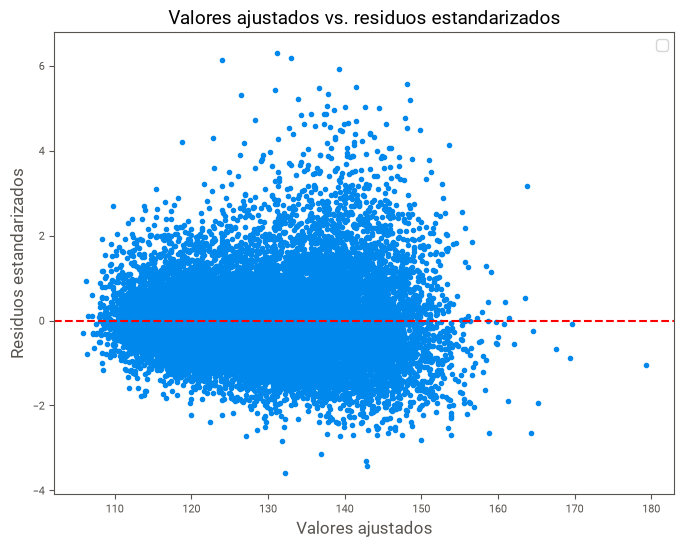

In [74]:
residuos_estandarizados = model.resid / model.resid.std()
plt.figure(figsize=(8, 6))
plt.scatter(model.fittedvalues, residuos_estandarizados)
plt.axhline(0, color='red', linestyle='--')
plt.xlabel("Valores ajustados", fontsize=12)
plt.ylabel("Residuos estandarizados", fontsize=12)
plt.title("Valores ajustados vs. residuos estandarizados", fontsize=14)
plt.legend()
plt.show()

9.1.5) QQ-plot, para analizar normalidad de los residuos

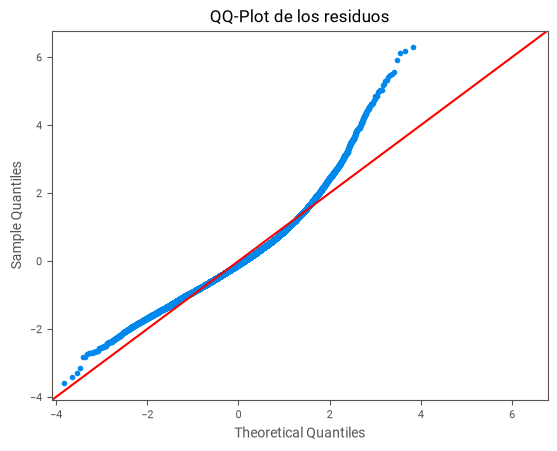

In [47]:
sm.qqplot(model.resid, line='45', fit=True)
plt.title("QQ-Plot de los residuos")
plt.show()

### 9.2) Hipotesis Multivariada de la catedra(promedio_sistolica, imc_bima, bima13,  bhch04, bimq05)

9.2.1) Separamos la variable objetivo(imc_bima) de las variables predictoras, para realizar una estandarizacion de estas ultimas

In [70]:
cols_hipotesis = ['imc_bima', 'promedio_sistolica', 'bima13', 'bhch04', 'bimq05']
df_hipotesis2 = preprocessed_dataset[cols_hipotesis].dropna().copy()
X = df_hipotesis2.drop('imc_bima', axis=1)
y = df_hipotesis2['imc_bima'].reset_index(drop=True)
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)
X_scaled_df = pd.DataFrame(X_scaled, columns=X.columns)

9.2.2) Analizamos los datos estandarizados para ajustar el modelo

In [71]:
print("Medias y desviaciones estándar antes del escalado:")
print(pd.DataFrame(X).describe().loc[['mean', 'std']])

print("\nMedias y desviaciones estándar después del escalado:")
print(pd.DataFrame(X_scaled_df).describe().loc[['mean', 'std']])

Medias y desviaciones estándar antes del escalado:
      promedio_sistolica     bima13     bhch04     bimq05
mean          129.946616  92.170867  46.246081  80.763247
std            20.893749  16.011371  17.923987  30.860160

Medias y desviaciones estándar después del escalado:
      promedio_sistolica        bima13        bhch04        bimq05
mean        1.748508e-16  6.768417e-17 -7.332451e-17  1.015262e-16
std         1.000099e+00  1.000099e+00  1.000099e+00  1.000099e+00


9.2.3) Ajustamos el modelo y realizamos su summary, paso por paso

In [72]:
X_scaleddf = sm.add_constant(X_scaled_df)

model2 = sm.OLS(y, X_scaleddf).fit()

print(model2.summary())

                            OLS Regression Results                            
Dep. Variable:               imc_bima   R-squared:                       0.647
Model:                            OLS   Adj. R-squared:                  0.647
Method:                 Least Squares   F-statistic:                     2305.
Date:                Sun, 08 Nov 2026   Prob (F-statistic):               0.00
Time:                        20:59:45   Log-Likelihood:                -13438.
No. Observations:                5039   AIC:                         2.689e+04
Df Residuals:                    5034   BIC:                         2.692e+04
Df Model:                           4                                         
Covariance Type:            nonrobust                                         
                         coef    std err          t      P>|t|      [0.025      0.975]
--------------------------------------------------------------------------------------
const                 28.1912      0

9.2.4) Analisis de homocedasticidad

C:\Users\facun\AppData\Local\Temp\ipykernel_4312\2095488029.py:8: UserWarning: No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.
  plt.legend()


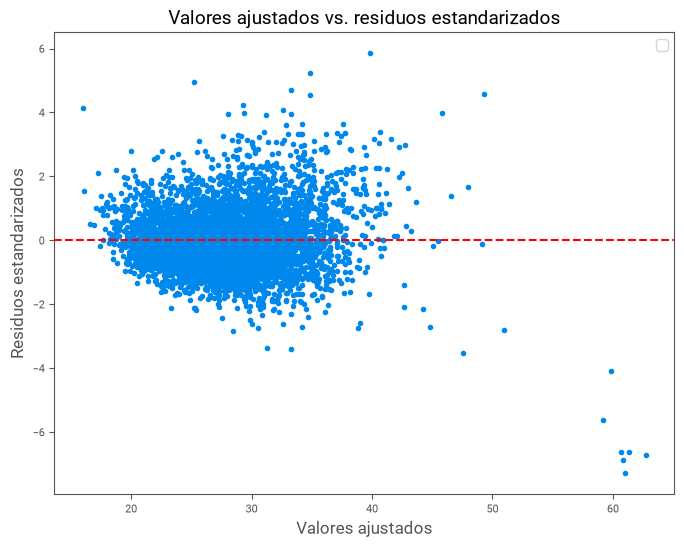

In [76]:
residuos_estandarizados = model2.resid / model2.resid.std()
plt.figure(figsize=(8, 6))
plt.scatter(model2.fittedvalues, residuos_estandarizados)
plt.axhline(0, color='red', linestyle='--')
plt.xlabel("Valores ajustados", fontsize=12)
plt.ylabel("Residuos estandarizados", fontsize=12)
plt.title("Valores ajustados vs. residuos estandarizados", fontsize=14)
plt.legend()
plt.show()

9.2.5) QQ-plot, para analizar normalidad de los residuos

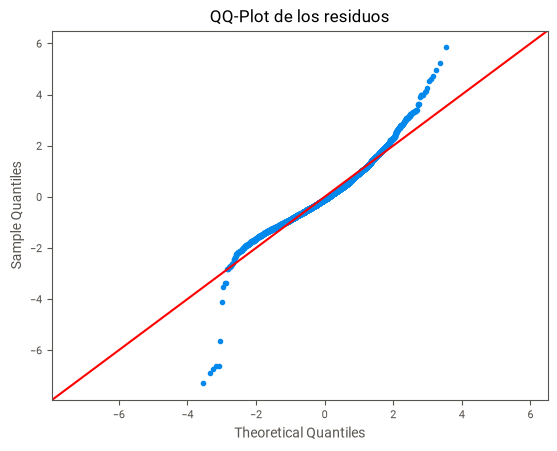

In [28]:
sm.qqplot(model.resid, line='45', fit=True)
plt.title("QQ-Plot de los residuos")
plt.show()